# Módulo 5 — Entregable: automatización multi-estación y cierre

Ejercicio 4 del Día 9 (automatización) + checkpoint de cierre del módulo
(ver [`README.md`](../README.md)).

> **📍 Nota para curso con 2 grupos — reparto de análisis, no de cómputo:** `evaluar_variable()` ya calcula las 5 métricas para las 6 estaciones en una sola tabla — no hace falta partir el cálculo. Lo que se reparte es la **interpretación**:
> - **Grupo 1** analiza y expone `bias`, `MAE`, `RMSE` de la tabla completa (sesgo y magnitud del error).
> - **Grupo 2** analiza y expone `r`, `KGE` de la misma tabla (patrón y diagnóstico compuesto).
> En la puesta en común se arma la lectura completa entre los dos grupos.
>
> **Extensión opcional (no evaluada) — Perú + ERA5-Land:** ver
> [`05_extension_opcional_peru_addedvalue.ipynb`](05_extension_opcional_peru_addedvalue.ipynb)
> para repetir el *added value* con las estaciones reales de Perú, si el grupo generó la descarga opcional del Módulo 3, Día 5.

In [1]:
import sys
sys.path.insert(0, ".")
import json
import numpy as np
import pandas as pd
import xarray as xr
from metricas import calcular_mae, calcular_rmse, calcular_bias, calcular_r, calcular_kge

## Función `evaluar_variable()`

In [2]:
def evaluar_variable(casos, nombre_variable="temperatura"):
    """casos: dict {nombre_estacion: (serie_observada, serie_simulada)}.
    Devuelve un DataFrame con una fila por estación y una columna por métrica.
    """
    filas = []
    for nombre_estacion, (obs, sim) in casos.items():
        assert (obs.index == sim.index).all(), f"Series no alineadas en {nombre_estacion}"
        kge, comp = calcular_kge(sim.values, obs.values)
        filas.append({
            "estacion": nombre_estacion,
            "variable": nombre_variable,
            "n_datos": len(obs),
            "MAE": calcular_mae(sim.values, obs.values),
            "RMSE": calcular_rmse(sim.values, obs.values),
            "bias": calcular_bias(sim.values, obs.values),
            "r": comp["r"],
            "KGE": kge,
        })
    return pd.DataFrame(filas).set_index("estacion").sort_values("RMSE")

## Ejecutar sobre el conjunto completo de estaciones de muestra

Las 6 estaciones reales dentro del dominio del WRF (`data/ogimet/coords_area_wrf.json`),
cada una con su observación real (SYNOP) y su WRF real interpolado al punto
más cercano, en las **24 horas del día completo** del `wrfout` de muestra
(`data/grid_muestra/wrfout_muestra.nc`, 2024-12-13).

In [3]:
coords = json.load(open("../../../data/ogimet/coords_area_wrf.json"))

# wrfout_muestra.nc: dia completo (24 horas), solo variables de superficie.
# No trae SINALPHA/COSALPHA -- no hacen falta (Modulo 4: en este dominio
# Mercator, U10/V10 crudos YA son earth-relative). Tampoco hace falta xwrf.
ds_wrf_es = xr.open_dataset("../../../data/grid_muestra/wrfout_muestra.nc")
tiempos = pd.to_datetime(ds_wrf_es["XTIME"].values)

def punto_mas_cercano(ds, lat, lon):
    dist2 = (ds["XLAT"] - lat) ** 2 + (ds["XLONG"] - lon) ** 2
    return np.unravel_index(np.argmin(dist2.values), dist2.shape)

casos = {}
for nombre, c in coords.items():
    iy, ix = punto_mas_cercano(ds_wrf_es, c["lat"], c["lon"])
    obs_horaria = pd.read_csv(f"../../../data/obs/{nombre}_2024_12_13_horario.csv",
                               parse_dates=["tiempo"]).set_index("tiempo")
    obs = obs_horaria.reindex(tiempos)["temp_C"]
    sim = pd.Series((ds_wrf_es["T2"].isel(south_north=iy, west_east=ix) - 273.15).values, index=tiempos)
    valido = obs.notna()
    casos[nombre] = (obs[valido], sim[valido])

tabla_resultados = evaluar_variable(casos, nombre_variable="temperatura_2m")
tabla_resultados.round(3)

,variable,n_datos,MAE,RMSE,bias,r,KGE
estacion,,,,,,,
Carrasco,temperatura_2m,23,1.555,1.735,1.555,0.976,0.704
Salto,temperatura_2m,24,1.540,1.997,0.962,0.888,0.405
Ezeiza,temperatura_2m,24,1.646,2.250,0.369,0.606,0.606
Rosario,temperatura_2m,24,1.949,2.348,0.652,0.927,0.653
Iguazu,temperatura_2m,24,2.554,2.856,1.681,0.442,0.121
Resistencia,temperatura_2m,24,2.567,2.918,2.444,0.661,0.494


In [4]:
tabla_resultados.round(3).to_csv("validacion_multiestacion.csv")
print("Archivo exportado: validacion_multiestacion.csv")
print()
print(f"Mejor desempeño (menor RMSE): {tabla_resultados.index[0]}")
print(f"Peor desempeño  (mayor RMSE): {tabla_resultados.index[-1]}")

Archivo exportado: validacion_multiestacion.csv

Mejor desempeño (menor RMSE): Carrasco
Peor desempeño  (mayor RMSE): Resistencia


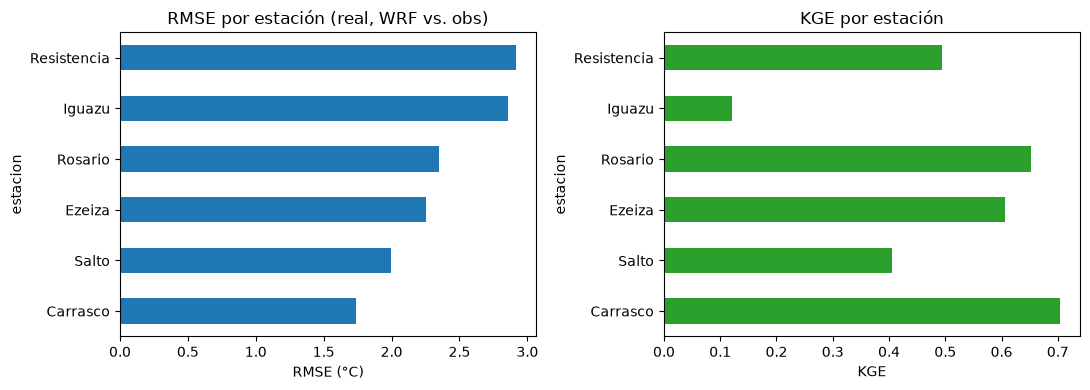

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
tabla_resultados["RMSE"].plot(kind="barh", ax=axes[0], color="tab:blue")
axes[0].set_xlabel("RMSE (°C)")
axes[0].set_title("RMSE por estación (real, WRF vs. obs)")
tabla_resultados["KGE"].plot(kind="barh", ax=axes[1], color="tab:green")
axes[1].set_xlabel("KGE")
axes[1].set_title("KGE por estación")
fig.tight_layout()
plt.show()

## Un caso mal hecho a propósito: latitud y longitud al revés

Arriba cada estación se comparó con el punto del WRF que le corresponde.
Ahora repetimos **exactamente el mismo cálculo** con un error muy común:
pasarle a la función `(lon, lat)` cuando espera `(lat, lon)`. Los datos
siguen siendo todos reales; solo cambia el orden de dos números.

In [6]:
casos_mal = {}
puntos_mal = {}
for nombre, c in coords.items():
    iy, ix = punto_mas_cercano(ds_wrf_es, c["lon"], c["lat"])   # ERROR: lon y lat al revés
    puntos_mal[nombre] = (float(ds_wrf_es["XLAT"][iy, ix]), float(ds_wrf_es["XLONG"][iy, ix]))
    obs, _ = casos[nombre]
    sim = pd.Series((ds_wrf_es["T2"].isel(south_north=iy, west_east=ix) - 273.15).values, index=tiempos)
    casos_mal[nombre] = (obs, sim[obs.index])

for nombre, c in coords.items():
    lat_u, lon_u = puntos_mal[nombre]
    print(f"{nombre:12s} estación en ({c['lat']:6.2f}, {c['lon']:6.2f}) -> punto WRF usado ({lat_u:6.2f}, {lon_u:6.2f})")

tabla_mal = evaluar_variable(casos_mal, nombre_variable="temperatura_2m")
columnas = ["bias", "RMSE", "r", "KGE"]
comparacion = pd.concat({"correcto": tabla_resultados[columnas],
                         "lat/lon al revés": tabla_mal[columnas]}, axis=1)
comparacion.round(2)

Carrasco     estación en (-34.83, -56.01) -> punto WRF usado (-36.82, -52.50)
Ezeiza       estación en (-34.82, -58.54) -> punto WRF usado (-36.82, -52.50)
Iguazu       estación en (-25.73, -54.48) -> punto WRF usado (-36.82, -52.50)
Resistencia  estación en (-27.44, -59.05) -> punto WRF usado (-36.82, -52.50)
Rosario      estación en (-32.91, -60.78) -> punto WRF usado (-36.82, -52.50)
Salto        estación en (-31.44, -57.98) -> punto WRF usado (-36.82, -52.50)


correcto                   lat/lon al revés                  
                bias  RMSE     r   KGE             bias  RMSE     r   KGE
estacion                                                                 
Carrasco        1.55  1.74  0.98  0.70            -1.77  2.60  0.66  0.04
Salto           0.96  2.00  0.89  0.40            -4.34  4.78  0.56 -0.01
Ezeiza          0.37  2.25  0.61  0.61            -2.94  3.80  0.48 -0.06
Rosario         0.65  2.35  0.93  0.65            -4.63  6.63  0.78  0.00
Iguazu          1.68  2.86  0.44  0.12            -3.42  3.74  0.08 -0.26
Resistencia     2.44  2.92  0.66  0.49            -4.01  4.53  0.10 -0.28

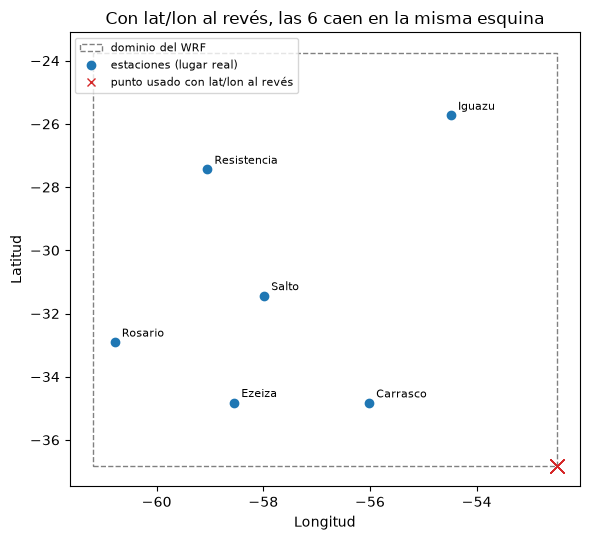

In [7]:
fig, ax = plt.subplots(figsize=(6, 5.5))
borde = [ds_wrf_es["XLONG"].min(), ds_wrf_es["XLONG"].max(), ds_wrf_es["XLAT"].min(), ds_wrf_es["XLAT"].max()]
ax.add_patch(plt.Rectangle((borde[0], borde[2]), borde[1] - borde[0], borde[3] - borde[2],
                           fill=False, linestyle="--", color="gray", label="dominio del WRF"))
for nombre, c in coords.items():
    ax.plot(c["lon"], c["lat"], "o", color="tab:blue")
    ax.annotate(nombre, (c["lon"], c["lat"]), textcoords="offset points", xytext=(5, 4), fontsize=8)
    lat_u, lon_u = puntos_mal[nombre]
    ax.plot(lon_u, lat_u, "x", color="tab:red", markersize=10)
ax.plot([], [], "o", color="tab:blue", label="estaciones (lugar real)")
ax.plot([], [], "x", color="tab:red", label="punto usado con lat/lon al revés")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title("Con lat/lon al revés, las 6 caen en la misma esquina")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

**Lectura honesta del resultado:** el código corrió **sin ningún
error** y produjo una tabla de métricas. Con lat/lon al revés, la
coordenada pedida (por ejemplo, latitud −58, longitud −34) cae fuera del
dominio, y la búsqueda del «punto más cercano» devuelve la esquina del
mapa, sobre el mar: **las 6 estaciones se comparan contra el mismo punto**.

Fíjate en `r`: en algunas estaciones sigue alto (0.78 en Rosario). El
ciclo de día y noche se parece en toda la región, así que `r` solo no
delata el error. Lo delatan el sesgo (todas entre −2 y −5 °C: el mar está
más fresco que tierra adentro) y el `KGE`, que cae a cero o menos.

Es la lección central del curso con datos reales: **que el código corra no
prueba que el resultado sea correcto.** Validar solo tiene sentido si el
punto del modelo y la estación corresponden al mismo lugar. La defensa es
barata: revisar a qué distancia quedó el punto encontrado y detenerse si
está demasiado lejos.

In [8]:
def punto_mas_cercano_seguro(ds, lat, lon, max_grados=0.1):
    """Como punto_mas_cercano(), pero avisa si el punto encontrado está lejos."""
    iy, ix = punto_mas_cercano(ds, lat, lon)
    distancia = float(np.hypot(ds["XLAT"][iy, ix] - lat, ds["XLONG"][iy, ix] - lon))
    if distancia > max_grados:
        raise ValueError(f"el punto más cercano está a {distancia:.1f}° de ({lat}, {lon}): "
                         "¿fuera del dominio o lat/lon al revés?")
    return iy, ix


c = coords["Ezeiza"]
try:
    punto_mas_cercano_seguro(ds_wrf_es, c["lon"], c["lat"])   # al revés
except ValueError as error:
    print("Detectado:", error)

print("Con el orden correcto:", punto_mas_cercano_seguro(ds_wrf_es, c["lat"], c["lon"]))

Detectado: el punto más cercano está a 28.0° de (-58.5422, -34.8183): ¿fuera del dominio o lat/lon al revés?
Con el orden correcto: (np.int64(81), np.int64(88))


## Valor añadido: ¿el WRF le gana al modelo global?

Con las 6 estaciones en su lugar correcto y el **día completo** (24 horas
UTC) del `wrfout` de muestra, agregamos ahora la pregunta del valor
añadido: ¿el WRF se acerca más a lo observado que el modelo global
(ERA5-Land)?

**Origen del dato observado:** no es el resumen climático diario de OGIMET
(`gsynres`, el que usa el Módulo Peru), sino los **mensajes SYNOP crudos**
de cada estación (binario `getsynop` de OGIMET), decodificados con
`pymetdecoder` para extraer temperatura, viento y precipitación **hora por
hora**. Los scripts que generan `data/obs/*_horario.csv`
(`data/h1_ogimet.py`, `data/h2_procesa_horario.py`) son herramientas de
preparación de datos, no parte del contenido del curso; lo que importa acá
es el resultado: observación real, hora real, punto real.

**Precipitación:** `RAINC`/`RAINNC` (WRF) y `tp` (ERA5-Land) son
acumulados que se **reinician una vez por día** (confirmado para esta
corrida) — por eso la lluvia de una hora específica se obtiene con
`.diff()` entre pasos consecutivos (la hora 00 UTC queda sin precipitación
calculable, porque no hay un paso anterior en este archivo para
diferenciar contra ella; se omite, no se inventa).

Con esto armamos la comparación de valor añadido completa y honesta:
**el mismo conjunto de estaciones y horas** se usa para WRF-vs-observación
y para ERA5-Land-vs-observación — ninguna de las dos comparaciones usa una
muestra distinta o más favorable que la otra.

In [9]:
import json

coords = json.load(open("../../../data/ogimet/coords_area_wrf.json"))
era5 = xr.open_dataset("../../../data/era_muestra/era5_land_20241213.nc")

# Mismo wrfout de día completo (24 horas) que arriba
ds_wrf = xr.open_dataset("../../../data/grid_muestra/wrfout_muestra.nc")
tiempos = pd.to_datetime(ds_wrf["XTIME"].values)

estaciones_area_wrf = list(coords.keys())

filas = []
for nombre in estaciones_area_wrf:
    c = coords[nombre]
    obs_horaria = pd.read_csv(f"../../../data/obs/{nombre}_2024_12_13_horario.csv",
                               parse_dates=["tiempo"]).set_index("tiempo").reindex(tiempos)
    iy, ix = punto_mas_cercano(ds_wrf, c["lat"], c["lon"])

    # Temperatura y viento: valores instantaneos, uno por hora, sin diferenciar.
    t2_wrf_h = ds_wrf["T2"].isel(south_north=iy, west_east=ix).values - 273.15
    vel_wrf_h = np.hypot(ds_wrf["U10"].isel(south_north=iy, west_east=ix).values,
                          ds_wrf["V10"].isel(south_north=iy, west_east=ix).values)
    t2_era5_h = era5["t2m"].sel(latitude=c["lat"], longitude=c["lon"], method="nearest").values - 273.15
    vel_era5_h = np.hypot(era5["u10"].sel(latitude=c["lat"], longitude=c["lon"], method="nearest").values,
                           era5["v10"].sel(latitude=c["lat"], longitude=c["lon"], method="nearest").values)

    # Precipitacion: acumulada desde el ultimo reinicio diario -- diferenciar
    # entre pasos consecutivos para obtener la lluvia de CADA hora.
    precip_wrf_acum = (ds_wrf["RAINC"] + ds_wrf["RAINNC"]).isel(south_north=iy, west_east=ix)
    precip_wrf_h = precip_wrf_acum.diff("XTIME").clip(min=0).values  # 23 valores (horas 1..23)
    precip_era5_acum_m = era5["tp"].sel(latitude=c["lat"], longitude=c["lon"], method="nearest")
    precip_era5_h = precip_era5_acum_m.diff("valid_time").clip(min=0).values * 1000  # m -> mm

    for i, t in enumerate(tiempos):
        fila = {
            "estacion": nombre, "hora_utc": t.hour,
            "temp_obs": obs_horaria["temp_C"].iloc[i], "temp_wrf": t2_wrf_h[i], "temp_era5": t2_era5_h[i],
            "vel_obs": obs_horaria["vel_viento_ms"].iloc[i], "vel_wrf": vel_wrf_h[i], "vel_era5": vel_era5_h[i],
            "precip_obs": np.nan, "precip_wrf": np.nan, "precip_era5": np.nan,
        }
        if i >= 1:  # la hora 0 no tiene paso anterior para diferenciar
            fila["precip_obs"] = obs_horaria["precip_mm"].iloc[i]
            fila["precip_wrf"] = precip_wrf_h[i - 1]
            fila["precip_era5"] = precip_era5_h[i - 1]
        filas.append(fila)

tabla_synop = pd.DataFrame(filas).dropna(subset=["temp_obs"])
print(f"n = {len(tabla_synop)} pares estación-hora (de {len(estaciones_area_wrf)} estaciones x {len(tiempos)} horas)")
tabla_synop.round(2)

n = 143 pares estación-hora (de 6 estaciones x 24 horas)


,estacion,hora_utc,temp_obs,temp_wrf,temp_era5,vel_obs,vel_wrf,vel_era5,precip_obs,precip_wrf,precip_era5
0,Carrasco,0,24.3,25.280001,23.330000,4.63,3.63,6.35,NaN,NaN,NaN
1,Carrasco,1,22.6,23.930000,22.200001,7.72,4.49,6.85,NaN,0.00,0.00
2,Carrasco,2,21.2,22.700001,21.200001,6.69,4.96,6.89,NaN,0.00,0.00
3,Carrasco,3,20.4,21.709999,20.490000,5.14,5.18,6.90,NaN,0.00,0.00
4,Carrasco,4,19.8,20.840000,20.030001,4.63,4.47,6.60,NaN,0.00,0.00
...,...,...,...,...,...,...,...,...,...,...,...
139,Salto,19,28.0,30.040001,25.240000,4.00,2.60,5.76,0.0,0.00,0.44
140,Salto,20,24.7,30.080000,25.080000,4.00,2.75,6.11,0.0,0.00,0.13
141,Salto,21,25.4,29.639999,25.129999,4.00,4.02,5.96,0.0,0.00,0.00
142,Salto,22,24.7,27.809999,24.660000,4.00,3.45,4.74,0.0,0.00,0.00


**Nota sobre viento:** validamos la **velocidad** (escalar, m/s), no la
dirección. La dirección es una variable circular (359° y 1° están a solo 2°
de distancia real, no a 358°) y `calcular_r`/`calcular_kge` asumen una
escala lineal — aplicarlos directo a grados produciría un error de patrón
casi arbitrario según dónde caiga el corte 0°/360°. Tratar bien variables
circulares requiere estadística distinta (correlación circular), fuera del
alcance de este módulo; se opta por no calcular una métrica que sería
matemáticamente inválida en vez de forzarla.

In [10]:
filas_metricas = []
for variable, unidad in [("temp", "°C"), ("vel", "m/s")]:
    o = tabla_synop[f"{variable}_obs"].values
    for fuente in ["wrf", "era5"]:
        s = tabla_synop[f"{variable}_{fuente}"].values
        kge_i, comp_i = calcular_kge(s, o)
        filas_metricas.append({
            "variable": variable, "unidad": unidad,
            "fuente": "WRF" if fuente == "wrf" else "Modelo global (ERA5-Land)",
            "n": len(o),
            "bias": calcular_bias(s, o), "MAE": calcular_mae(s, o), "RMSE": calcular_rmse(s, o),
            "r": comp_i["r"], "KGE": kge_i,
        })

tabla_valor_agregado = pd.DataFrame(filas_metricas).set_index(["variable", "fuente"])
tabla_valor_agregado.round(3)

unidad    n   bias    MAE   RMSE      r  \
variable fuente                                                              
temp     WRF                           °C  143  1.275  1.971  2.393  0.759   
         Modelo global (ERA5-Land)     °C  143  0.368  1.333  1.779  0.805   
vel      WRF                          m/s  143  0.056  1.503  2.072  0.182   
         Modelo global (ERA5-Land)    m/s  143 -0.403  1.404  1.873  0.365   

                                      KGE  
variable fuente                            
temp     WRF                        0.753  
         Modelo global (ERA5-Land)  0.687  
vel      WRF                        0.162  
         Modelo global (ERA5-Land)  0.331

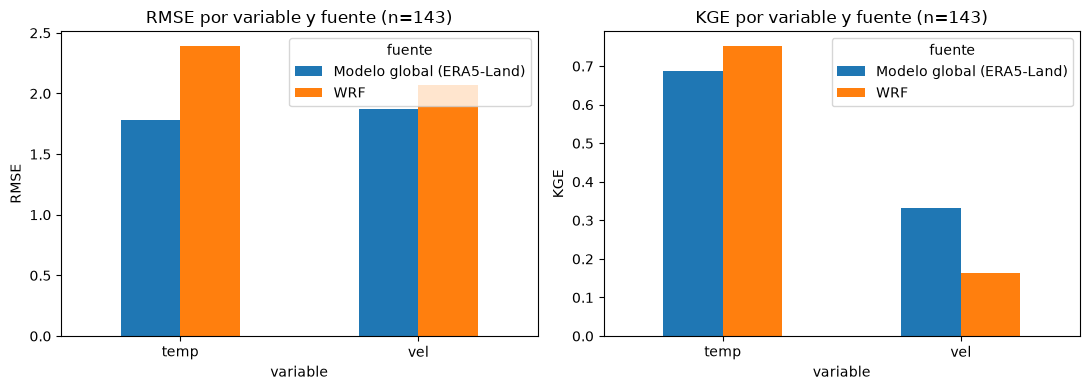

In [11]:
n_th = len(tabla_synop)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
tabla_valor_agregado["RMSE"].unstack("fuente").plot(kind="bar", ax=axes[0])
axes[0].set_ylabel("RMSE")
axes[0].set_title(f"RMSE por variable y fuente (n={n_th})")
axes[0].tick_params(axis="x", rotation=0)
tabla_valor_agregado["KGE"].unstack("fuente").plot(kind="bar", ax=axes[1])
axes[1].set_ylabel("KGE")
axes[1].set_title(f"KGE por variable y fuente (n={n_th})")
axes[1].tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()

**Lectura honesta del resultado:** esta sí es una comparación de valor
añadido válida: mismas estaciones y mismas horas para los dos lados (143
pares estación-hora).

El resultado **no favorece claramente al WRF**. En temperatura, ERA5-Land
gana en sesgo, MAE, RMSE y `r`, pero el WRF gana en `KGE` (0.75 frente a
0.69): las métricas no siempre coinciden, y por eso se reportan varias.

**Cuidado con ese KGE «agregado».** La tabla junta los 143 pares de las 6
estaciones en una sola serie. Así, parte de la variabilidad que miden `r` y
`alpha` es la diferencia **entre estaciones** (unas son más cálidas que
otras todo el día), que cualquier modelo reproduce con facilidad. Si
calculas el KGE **estación por estación**, el WRF pierde frente a ERA5-Land
en casi todas (en Salto, 0.41 frente a 0.64: Ejercicio 4 del Día 8). Antes
de concluir «el WRF gana en KGE», revisa siempre las métricas por estación. En
viento, ninguno reproduce bien el patrón hora a hora (`r` de 0.18 para el
WRF y 0.37 para ERA5-Land).

Esto no es un error del ejercicio ni del WRF: a veces el modelo de alta
resolución no le gana al modelo global, y reportarlo así (sin ocultarlo ni
forzar que «el WRF gane») es la práctica correcta.

In [12]:
# Precipitacion: RAINC/RAINNC (WRF) y tp (ERA5-Land) ya estan diferenciados
# hora a hora (celda anterior). El dato observado horario de 1h solo esta
# disponible en Salto (las demas estaciones no reportaron ese grupo SYNOP
# ningun dia) -- se calculan metricas igual, con el n real que hay, sin
# inventar datos en las estaciones que no lo tienen.
con_precip = tabla_synop.dropna(subset=["precip_obs"])
print(f"Pares estación-hora con precipitación horaria observable: {len(con_precip)} de {len(tabla_synop)}")
print("Estaciones presentes:", sorted(con_precip['estacion'].unique()))
con_precip[["estacion", "hora_utc", "precip_obs", "precip_wrf", "precip_era5"]].round(2)

Pares estación-hora con precipitación horaria observable: 23 de 143
Estaciones presentes: ['Salto']


,estacion,hora_utc,precip_obs,precip_wrf,precip_era5
121,Salto,1,0.0,0.00,0.00
122,Salto,2,0.0,0.00,0.00
123,Salto,3,0.0,0.00,0.00
124,Salto,4,0.0,0.88,0.00
125,Salto,5,0.0,15.15,0.00
126,Salto,6,0.0,9.46,0.04
127,Salto,7,0.0,1.82,0.00
128,Salto,8,0.0,2.29,0.06
129,Salto,9,3.0,4.15,0.01
130,Salto,10,4.0,2.15,0.00


In [13]:
o_p = con_precip["precip_obs"].values
filas_precip = []
for fuente in ["wrf", "era5"]:
    s_p = con_precip[f"precip_{fuente}"].values
    filas_precip.append({
        "fuente": "WRF" if fuente == "wrf" else "Modelo global (ERA5-Land)",
        "n": len(o_p), "bias": calcular_bias(s_p, o_p), "MAE": calcular_mae(s_p, o_p),
        "RMSE": calcular_rmse(s_p, o_p), "r": calcular_r(s_p, o_p),
    })
tabla_precip_av = pd.DataFrame(filas_precip).set_index("fuente").round(3)
tabla_precip_av

,n,bias,MAE,RMSE,r
fuente,,,,,
WRF,23,1.358,1.738,3.972,0.048
Modelo global (ERA5-Land),23,-0.331,0.534,1.241,-0.135


**Lectura honesta (precipitación):** con n pequeño (una sola estación real
con el grupo SYNOP de 1 h) y precipitación —el campo más difícil de
validar en general, por su variabilidad espacial fina—, `r` sale bajo o
negativo para ambas fuentes: ni WRF ni ERA5-Land ubican bien el momento
exacto de la lluvia observada en Salto ese día. Esto no invalida el
método (`.diff()` sobre el acumulado diario, ya verificado); es el
resultado real de comparar precipitación puntual y horaria, donde incluso
modelos operativos serios tienen skill bajo.

El diagrama de Taylor de esta comparación (referencia + WRF + ERA5-Land,
con `SkillMetrics`) se construye en
[`03_practica_dia9_taylor_addedvalue.ipynb`](03_practica_dia9_taylor_addedvalue.ipynb)
— la tabla de arriba es su contraparte numérica agregada (día completo,
todas las estaciones) en vez de una sola estación de referencia.

## Checkpoint de cierre del módulo

**Pregunta:** ¿por qué un modelo puede tener `r` alto y `KGE` bajo al mismo
tiempo, y qué comparación adicional hace falta para hablar de "valor
añadido" de forma rigurosa?

✍️ **Tu respuesta** (doble clic en esta celda y escribe debajo):

…

<details>
<summary>Ver una respuesta modelo (ábrela solo después de escribir la tuya)</summary>

<pre>
r alto solo mide que el PATRON de variacion se sigue bien (sube cuando sube,
baja cuando baja), pero no dice nada sobre el sesgo (beta) ni sobre si la
amplitud de la variabilidad esta bien representada (alpha). Un modelo puede
seguir perfectamente el patron observado pero estar sistematicamente 3
grados por encima (r~1, beta muy distinto de 1) -- eso arrastra el KGE hacia
abajo aunque r sea excelente.

Para hablar de "valor anadido" de forma rigurosa no basta con validar el
WRF solo: hace falta la comparacion PARALELA contra el modelo global (ERA5
o GFS, interpolado a la misma ubicacion) frente a la misma observacion de
referencia. Solo si el WRF mejora las metricas frente a ese modelo global
(no solo frente a un umbral absoluto) hay evidencia de que la simulacion de
alta resolucion esta aportando algo que el dato global no tenia. En la
practica ese modelo global suele ser el mismo que forzo al WRF (Modulo 3),
pero aqui se usa como el otro extremo de la comparacion, no como la
observacion de verdad.
</pre>
</details>

---
**Fin del Módulo 5.** Siguiente:
[Módulo 6 — Pipeline integrado](../../modulo_06_pipeline_integrado/README.md).